Câu 1: Tạo mới một tập tin notebook và import vào các thư viện thao tác với tập dữ liệu và số: numpy, pandas, thư viện vẽ đồ thị, trực quan hóa dữ liệu: seaborn, matplotlib.

In [ ]:
#linear algebra
import numpy as np

#data processing
import pandas as pd

#data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style

In [ ]:
print("Nguyễn Duy Bình - 6451071005")
with open('titanic.csv') as f:
    df = pd.read_csv(
        f,
        dtype={
            'age': np.float64,
            'sibsp': np.int64,
            'parch': np.int64
        }
    )

print(df.head())

Nguyễn Duy Bình - 6451071005
   pclass  survived                                             name     sex  \
0       1         1                    Allen, Miss. Elisabeth Walton  female   
1       1         1                   Allison, Master. Hudson Trevor    male   
2       1         0                     Allison, Miss. Helen Loraine  female   
3       1         0             Allison, Mr. Hudson Joshua Creighton    male   
4       1         0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.des

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB
None


In [ ]:
print(df.describe())

            pclass     survived          age        sibsp        parch  \
count  1309.000000  1309.000000  1046.000000  1309.000000  1309.000000   
mean      2.294882     0.381971    29.881135     0.498854     0.385027   
std       0.837836     0.486055    14.413500     1.041658     0.865560   
min       1.000000     0.000000     0.166700     0.000000     0.000000   
25%       2.000000     0.000000    21.000000     0.000000     0.000000   
50%       3.000000     0.000000    28.000000     0.000000     0.000000   
75%       3.000000     1.000000    39.000000     1.000000     0.000000   
max       3.000000     1.000000    80.000000     8.000000     9.000000   

              fare        body  
count  1308.000000  121.000000  
mean     33.295479  160.809917  
std      51.758668   97.696922  
min       0.000000    1.000000  
25%       7.895800   72.000000  
50%      14.454200  155.000000  
75%      31.275000  256.000000  
max     512.329200  328.000000  


Câu 2

In [ ]:
print("Nguyễn Duy Bình - 6451071005")
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum()/df.isnull().count()*100
percent_2 = (round(percent_1,1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis = 1, keys=['Total', '%'])
print(missing_data.head(5))

Nguyễn Duy Bình - 6451071005
           Total     %
body        1188  90.8
cabin       1014  77.5
boat         823  62.9
home.dest    564  43.1
age          263  20.1


Câu 3: Xem xét thống kê giữa thuộc tính Độ tuổi (age), Giới tính (sex) và khả năng sống sót
(survived)

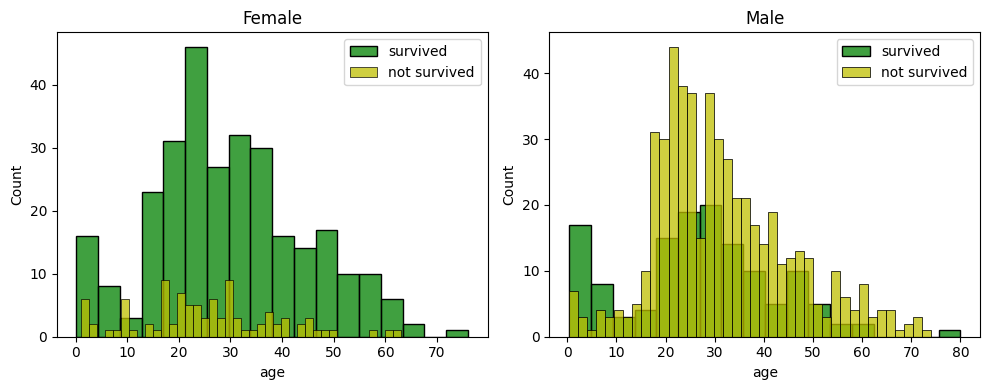

In [ ]:
survived = 'survived'
not_survived = 'not survived'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

# Phân chia dữ liệu theo giới tính
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ Female
ax = sns.histplot(
    women[women['survived'] == 1]['age'].dropna(),
    bins=18,
    label=survived,
    ax=axes[0],
    kde=False,
    color='g'
)

ax = sns.histplot(
    women[women['survived'] == 0]['age'].dropna(),
    bins=40,
    label=not_survived,
    ax=axes[0],
    kde=False,
    color='y'
)

ax.legend()
ax.set_title('Female')

# Biểu đồ Male
ax = sns.histplot(
    men[men['survived'] == 1]['age'].dropna(),
    bins=18,
    label=survived,
    ax=axes[1],
    kde=False,
    color='g'
)

ax = sns.histplot(
    men[men['survived'] == 0]['age'].dropna(),
    bins=40,
    label=not_survived,
    ax=axes[1],
    kde=False,
    color='y'
)

ax.legend()
ax.set_title('Male')

plt.tight_layout()
plt.show()

Câu 4: Xem xét thống kê giữa thuộc tính Cổng lên tàu (embarked) và loại vé (pclass) với
khả năng sống sót (survived), phân biệt theo Giới tính (sex).

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)


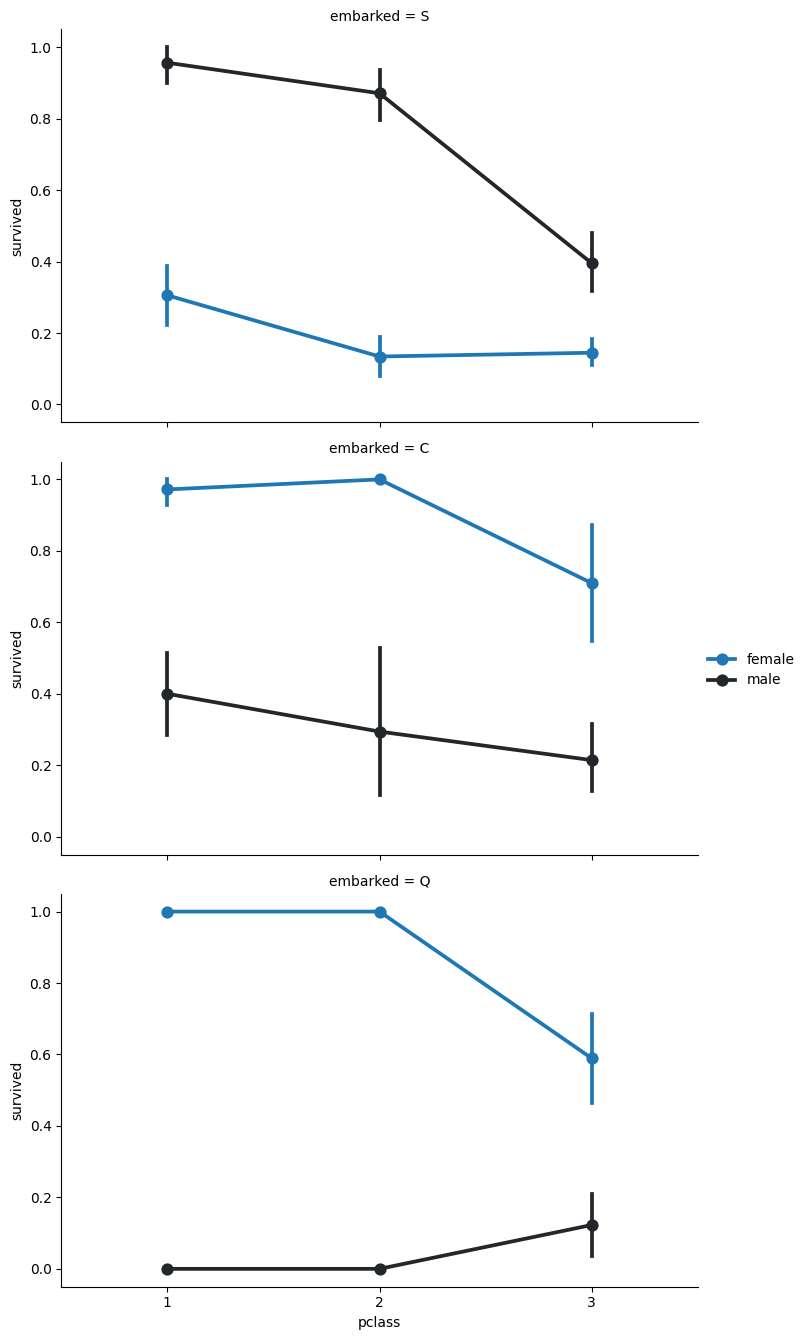

In [ ]:
FacetGrid = sns.FacetGrid(df, row='embarked', height = 4.5, aspect = 1.6)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette =None, order=None, hue_order=None)
FacetGrid.add_legend()

<Axes: xlabel='pclass', ylabel='survived'>

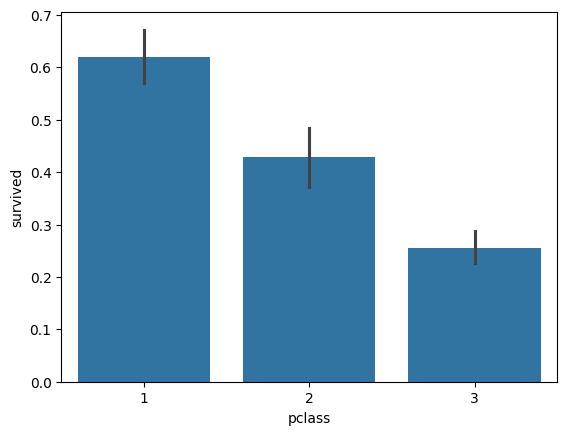

In [ ]:
sns.barplot(x='pclass', y='survived', data=df)

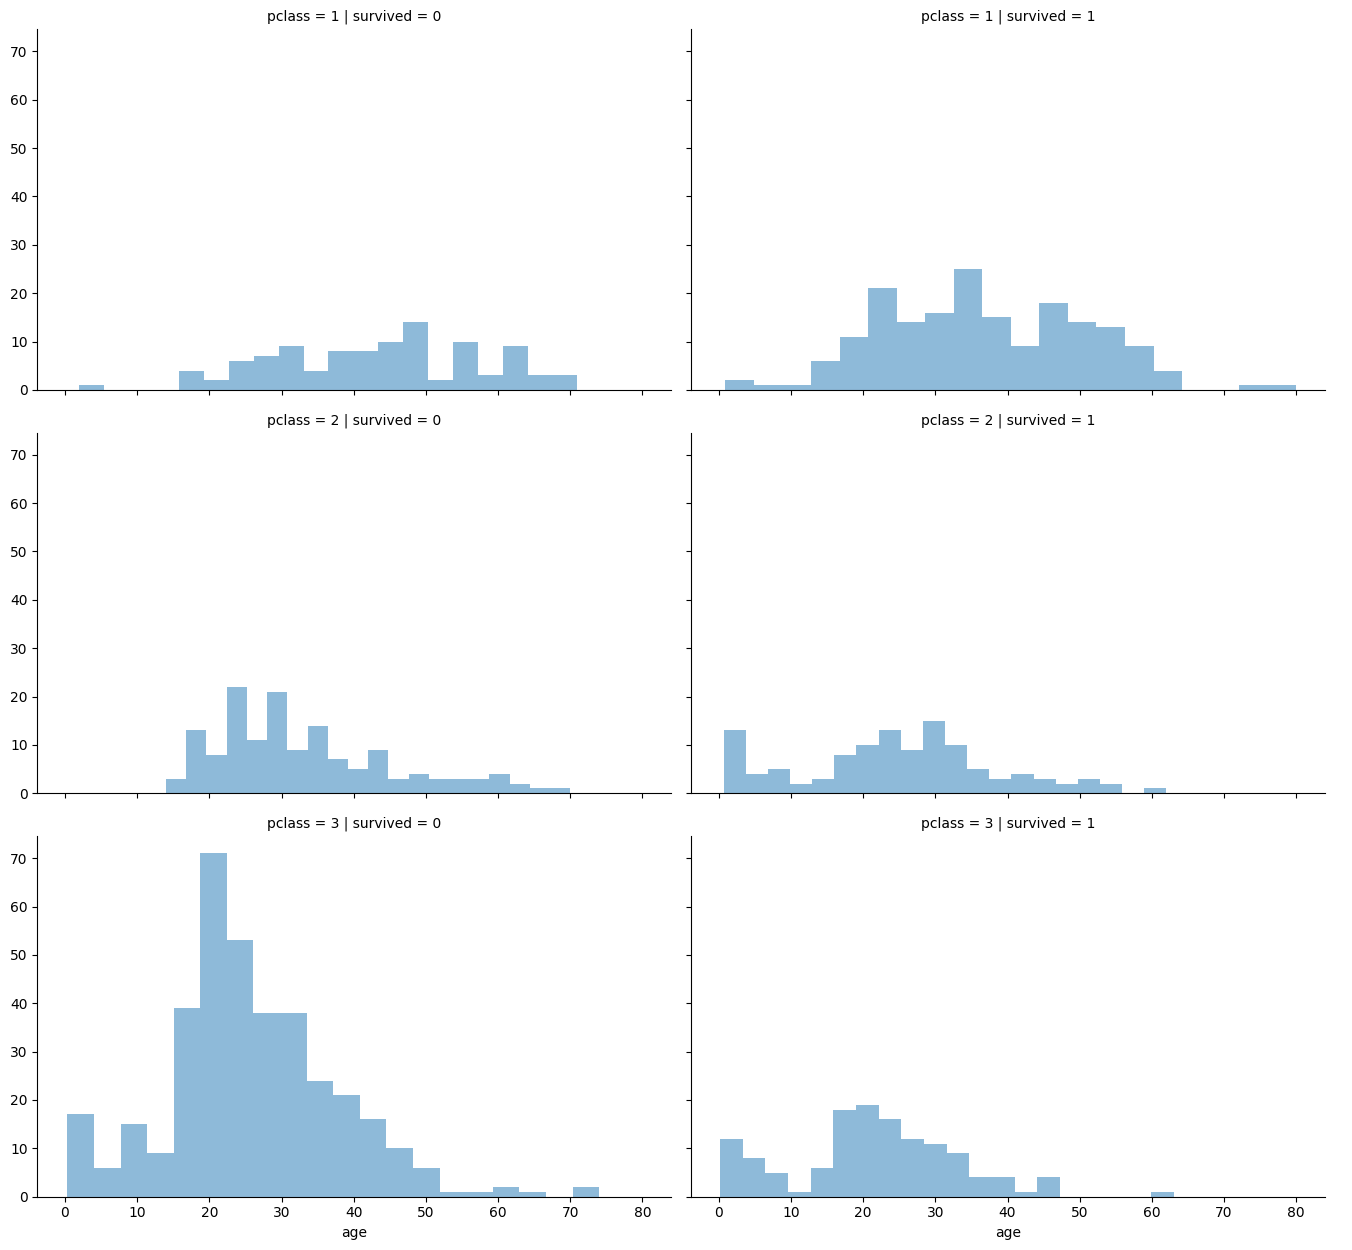

In [ ]:
grid = sns.FacetGrid(df, col= 'survived', row='pclass', height=4.2, aspect =1.6)
grid.map(plt.hist, 'age', alpha =.5, bins = 20)
grid.add_legend();

Câu 5: Thống kê số người đi cùng (anh chị em/vợ chồng hoặc cha mẹ/con cái)

In [ ]:
for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']

    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1

    dataset['not_alone'] = dataset['not_alone'].astype(int)

df['not_alone'].value_counts()

,count
not_alone,
1,790
0,519


Vẽ biểu đồ biểu diễn mối quan hệ giữa số người đi cùng và khả năng sống sót


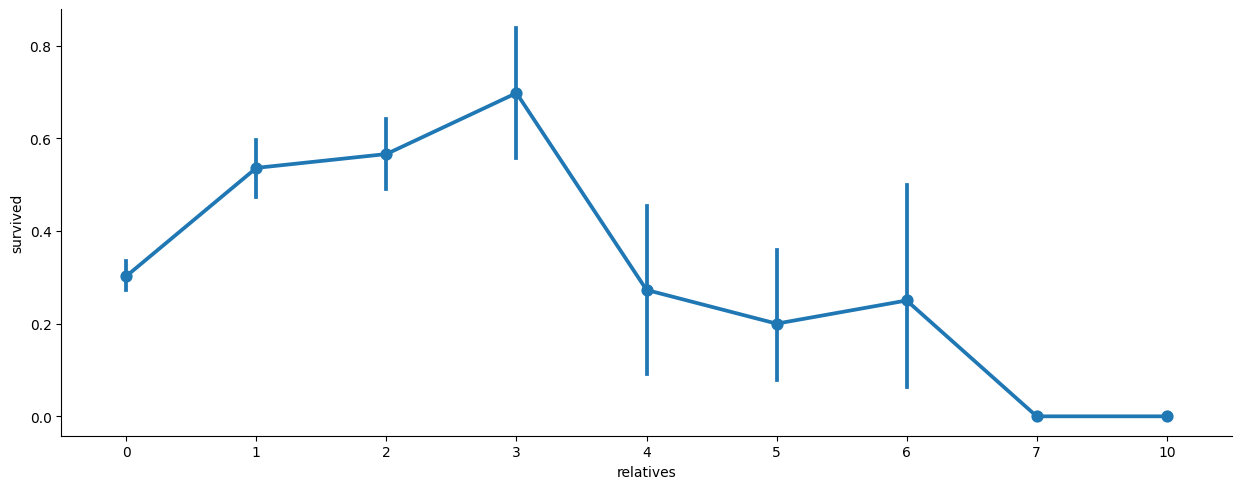

In [ ]:
axes = sns.catplot(
    x='relatives',
    y='survived',
    data=df,
    aspect=2.5,
    kind='point'
)

Câu 6: Tiền xử lý dữ liệu

In [ ]:
df = pd.read_csv('titanic.csv')

In [ ]:
import re

deck = {
    "A": 1,
    "B": 2,
    "C": 3,
    "D": 4,
    "E": 5,
    "F": 6,
    "G": 7,
    "U": 8
}

for dataset in [df]:
    dataset['cabin'] = dataset['cabin'].fillna("U")

    dataset['deck'] = dataset['cabin'].map(
        lambda x: re.compile(r"([a-zA-Z]+)").search(x).group()
    )

    dataset['deck'] = dataset['deck'].map(deck)
    dataset['deck'] = dataset['deck'].fillna(0)
    dataset['deck'] = dataset['deck'].astype(int)

# We can now drop the cabin feature
df = df.drop(['cabin'], axis=1)

In [ ]:
df['ticket'].describe()

,ticket
count,1309
unique,929
top,CA. 2343
freq,11


Có thể thấy thuộc tính ticket có đến 929 giá trị khác nhau, có khả năng thuộc tính này
sẽ không giúp ích được trong quá trình khai thác, ngược lại còn gây sai số cho thuật toán
nên có thể xóa nó đi.

Thực hiện xóa các thuộc tính không cần thiết.


In [ ]:
df = df.drop(['ticket'], axis=1)
df = df.drop(['boat'], axis=1)
df = df.drop(['body'], axis=1)
df = df.drop(['home.dest'], axis=1)

Các giá trị này sẽ được sinh ngẫu nhiên dựa vào giá trị trung bình, độ lệch chuẩn và số
các giá trị còn thiếu

In [ ]:
import numpy as np

for dataset in [df]:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()

    # Compute random numbers between the mean, std and is_null
    rand_age = np.random.randint(
        mean - std,
        mean + std,
        size=is_null
    )

    # Fill NaN values in Age column with random values generated
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age

    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)

df["age"].isnull().sum()

np.int64(0)

In [ ]:
df['embarked'].describe()

,embarked
count,1307
unique,3
top,S
freq,914


Ta thấy, giá trị ‘S’ là phổ biến nhất, nên có thể chọn nó đề điền vào các vị trí còn trống.

In [ ]:
common_value = 'S'

for dataset in [df]:
  dataset['embarked'] = dataset['embarked'].fillna(common_value)

Xem xét lại các thuộc tính

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   object 
 3   sex       1309 non-null   object 
 4   age       1309 non-null   int64  
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   fare      1308 non-null   float64
 8   embarked  1309 non-null   object 
 9   deck      1309 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 102.4+ KB
